In [1]:
from civic.util import load_dump

df = load_dump('../data/civic-dump.jsonl')
print(df.columns)
df['variantOrigin'].value_counts(dropna=False)

Index(['description', 'evidenceDirection', 'evidenceLevel', 'evidenceRating',
       'evidenceType', 'flagged', 'id', 'phenotypes', 'significance', 'status',
       'therapies', 'therapyInteractionType', 'variantOrigin',
       'disease.diseaseAliases', 'disease.doid', 'disease.id', 'disease.name',
       'events', 'molecularProfile.id', 'molecularProfile.name',
       'molecularProfile.variants', 'revisions.nodes', 'source.citationId',
       'source.name', 'source.pmcId', 'source.sourceType', 'pmid',
       'submittedBy', 'submittedAt', 'acceptedBy', 'acceptedAt', 'rejectedBy',
       'rejectedAt'],
      dtype='object')


variantOrigin
SOMATIC            7357
RARE_GERMLINE      3099
NA                  636
UNKNOWN             347
COMMON_GERMLINE      92
COMBINED             23
MIXED                 9
Name: count, dtype: int64

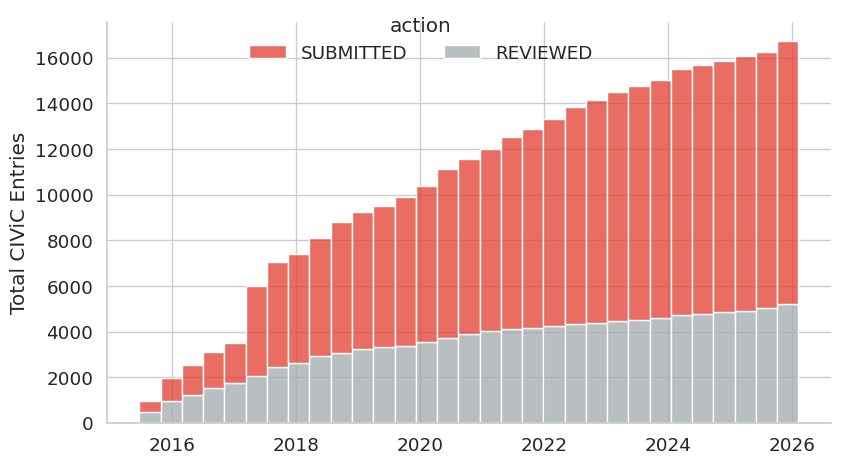

In [25]:
import pandas as pd
import seaborn as sns
from figutils.util import generate_hue_map

BC_CANCER_PALETTE = sns.color_palette(['#2ec7d6', '#9e4dab'])



# make cumulative accepted/submitted counts
df['SUBMITTED'] = pd.to_datetime(df.submittedAt)
df['REVIEWED'] = pd.to_datetime(df.acceptedAt)
df.loc[df.REVIEWED.isna(), 'REVIEWED'] =  pd.to_datetime(df[df.REVIEWED.isna()]['rejectedAt'])
sns.set_style('whitegrid')

with sns.plotting_context("notebook", font_scale=1.2):

    fig_df = pd.melt(df, id_vars=[c for c in df.columns if c not in {'SUBMITTED', 'REVIEWED'}], value_name='timestamp', value_vars=['SUBMITTED', 'REVIEWED'], var_name='action')
    ax = sns.displot(data=fig_df, x='timestamp', hue='action', cumulative=True, palette={'SUBMITTED': '#e33c30', 'REVIEWED': '#a2a9ad'}, multiple='stack', kind='hist', aspect=1.75)
    ax.set(ylabel='Total CIViC Entries', xlabel='')
    sns.move_legend(ax, 'upper center', ncols=2)
    df.status.value_counts(normalize=True)

# sns.histplot(data=df, x='acceptedAt', cumulative=True, ax=ax)

In [6]:
stats_df = df[['evidenceType']].value_counts(normalize=True).reset_index(name='evidence_type_freq').merge(df[['evidenceType', 'evidenceLevel']].value_counts(normalize=True).reset_index(name='freq'))
stats_df['relative_freq'] = stats_df.freq / stats_df.evidence_type_freq

stats_df = stats_df[stats_df.relative_freq >= 0.05]
stats_df.sort_values(['evidenceType'])

,evidenceType,evidence_type_freq,evidenceLevel,freq,relative_freq
15,DIAGNOSTIC,0.063555,B,0.036800,0.579019
16,DIAGNOSTIC,0.063555,C,0.021301,0.335150
17,DIAGNOSTIC,0.063555,A,0.003810,0.059946
20,FUNCTIONAL,0.059053,D,0.057581,0.975073
24,ONCOGENIC,0.051087,D,0.017924,0.350847
25,ONCOGENIC,0.051087,C,0.016538,0.323729
26,ONCOGENIC,0.051087,E,0.012815,0.250847
27,ONCOGENIC,0.051087,B,0.003723,0.072881
0,PREDICTIVE,0.492857,D,0.194303,0.394238
1,PREDICTIVE,0.492857,C,0.146073,0.296381


In [7]:
# get user data
from civic.download import page_civic_nodes

query_body = '''\
displayName
username
id
joinDate
role
statsHash {
    acceptedAssertions
    acceptedEvidenceItems
    appliedRevisions
    comments
    revisions
    submittedAssertions
    submittedEvidenceItems
    suggestedSources
}
'''

users = page_civic_nodes('users', query_body)
user_df = pd.DataFrame.from_records(users)
user_df

,displayName,username,id,joinDate,role,statsHash
0,AdamCoffman,AdamCoffman,1,2015-02-26T02:44:20Z,ADMIN,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
1,JoshMcMichael,JoshMcMichael,2,2015-02-26T02:48:45Z,ADMIN,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
2,ObiGriffith,ObiGriffith,3,2015-02-26T02:53:49Z,ADMIN,"{'acceptedAssertions': 2, 'acceptedEvidenceIte..."
3,BenAinscough,BenAinscough,5,2015-02-26T04:09:15Z,EDITOR,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
4,kkrysiak,kkrysiak,6,2015-02-26T04:14:20Z,ADMIN,"{'acceptedAssertions': 4, 'acceptedEvidenceIte..."
...,...,...,...,...,...,...
2681,PaulLott_1,PaulLott_1,2844,2026-02-03T22:01:19Z,CURATOR,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
2682,Instoncai,Instoncai,2845,2026-02-04T08:04:13Z,CURATOR,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
2683,SebastianSaldivar,SebastianSaldivar,2846,2026-02-04T21:47:21Z,CURATOR,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."
2684,MaSlots,MaSlots,2847,2026-02-05T05:53:46Z,CURATOR,"{'acceptedAssertions': 0, 'acceptedEvidenceIte..."


/projects/creisle_prj/git/civicfact/data_builder/.venv/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/projects/creisle_prj/git/civicfact/data_builder/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


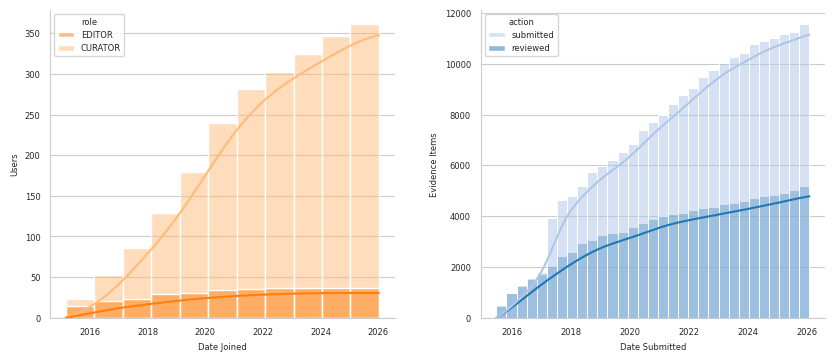

In [8]:
from matplotlib import pyplot as plt
from matplotlib import gridspec

from figutils.util import generate_hue_map


hue_map = generate_hue_map(['reviewed', 'submitted', 'EDITOR', 'CURATOR'], 'tab20')


fig = plt.figure(figsize=(10, 4), layout='tight')
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.25)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

user_df['activity_count'] = user_df.statsHash.apply(lambda s: sum(s.values()))
user_df['joinDate'] = pd.to_datetime(user_df.joinDate)
user_df['freq'] = 1
user_df = user_df[~user_df.joinDate.isna()]
fig_df = user_df.copy()
fig_df.loc[fig_df.role == 'ADMIN', 'role'] = 'EDITOR'
fig_df.loc[(fig_df.role == 'CURATOR') & (fig_df.activity_count == 0), 'role'] = 'USER'

sns.histplot(data=fig_df[fig_df.role != 'USER'], x='joinDate', hue='role', cumulative=True, kde=True, palette=hue_map, ax=ax1)
ax1.set_xlabel('Date Joined')
ax1.set_ylabel('Users')



sns.set_style('whitegrid')
# make cumulative accepted/submitted counts
df['submitted'] = pd.to_datetime(df.submittedAt)
df['reviewed'] = pd.to_datetime(df.acceptedAt)
df.loc[df.reviewed.isna(), 'reviewed'] =  pd.to_datetime(df[df.reviewed.isna()]['rejectedAt'])

fig_df = pd.melt(df, id_vars=[c for c in df.columns if c not in {'submitted', 'reviewed'}], value_name='timestamp', value_vars=['submitted', 'reviewed'], var_name='action')
sns.histplot(data=fig_df, x='timestamp', hue='action', cumulative=True, kde=True, palette=hue_map, ax=ax2)
ax2.set_ylabel('Evidence Items')
ax2.set_xlabel('Date Submitted')

for ax in [ax1, ax2]:
    ax.xaxis.grid(False)
    ax.spines[['right', 'top']].set_visible(False)
